# Clase 6 — De la tabla a la red

**Mini curso "RL a ciegas" · vía profunda (notebooks)**

Hasta ahora el agente guardaba lo que sabía en una **tabla** $Q(s,a)$: una fila por casilla, una columna por acción.
En la cueva hay unas decenas de casillas y la tabla entra cómoda. En un juego de Atari el "estado" es la **pantalla**:
84×84 pixeles con 256 tonos de gris → más pantallas posibles que átomos en el universo. Ninguna tabla alcanza.

La salida es reemplazar la tabla por una **función aprendida**: una **red neuronal** que recibe una descripción del
estado y devuelve los 4 valores $Q(s,\cdot)$. Eso es **Deep RL**, y el algoritmo que lo hizo famoso es
**DQN** (*Deep Q-Network*, Mnih et al., *Nature* 2015).

Plan:

| Paso | Qué hacemos |
|---|---|
| 1 | Una red con entrada *one-hot* **es** la tabla (lo comprobamos) |
| 2 | DQN con una entrada más rica: posición + 4 "bigotes" que sienten paredes |
| 3 | Qué aprendió la red: $V(s)$, política y trayectoria |
| 4 | Generalización: valores para casillas que casi no visitó |
| 5 | Ablación: ¿qué pasa sin *replay buffer*? |

## Preparación

La primera celda escribe el entorno `cave_env.py` (el mismo de todas las clases), así el notebook funciona solo en Colab.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 3 (con modelo): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Imports y semillas fijas. Usamos **PyTorch** en CPU (en Colab ya viene instalado).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from cave_env import CaveEnv, ACTION_NAMES

np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(1)      # en redes tan chicas, un hilo es más rápido
plt.rcParams["figure.dpi"] = 90

### Herramientas

Funciones largas (Q-learning tabular, DQN, dibujos). **No hace falta leerlas**: en la clase solo las usamos.
En Colab aparece plegada.

In [3]:
#@title Herramientas (plegable)
# Herramientas: no hace falta leer esto
import time

AZUL, NARANJA = "#2a78d6", "#eb6834"

def iteracion_de_valor(env, gamma=0.95, tol=1e-8):
    """V* exacto usando el modelo (clase 3). Sirve de referencia."""
    V = np.zeros(env.nS)
    while True:
        Qm = env.R + gamma * env.P @ V
        V2 = Qm.max(1)
        if np.abs(V2 - V).max() < tol:
            return V2, Qm.argmax(1)
        V = V2

def epsilon(paso, eps_ini=1.0, eps_fin=0.05, pasos_decaimiento=4000):
    return max(eps_fin, eps_ini - (eps_ini - eps_fin) * paso / pasos_decaimiento)

def transiciones_al_azar(env, n=3000, seed=0):
    """Una lista fija de transiciones (s, a, r, s', terminal) con un agente al azar."""
    rng = np.random.default_rng(seed); out = []
    s = env.reset()
    for _ in range(n):
        a = int(rng.integers(4)); s2, r, done, info = env.step(a)
        out.append((s, a, r, s2, info["reached_goal"]))
        s = env.reset() if done else s2
    return out

def q_tabla(env, transiciones, alpha=0.5, gamma=0.95):
    Q = np.zeros((env.nS, 4))
    for s, a, r, s2, fin in transiciones:
        y = r + (0.0 if fin else gamma * Q[s2].max())
        Q[s, a] += alpha * (y - Q[s, a])
    return Q

def q_red_onehot(env, transiciones, alpha=0.5, gamma=0.95):
    """Una red lineal sin sesgo (nS -> 4), entrada one-hot, SGD con lr = alpha, pérdida ½(Q - y)²."""
    red = nn.Linear(env.nS, 4, bias=False).double()
    nn.init.zeros_(red.weight)
    opt = torch.optim.SGD(red.parameters(), lr=alpha)
    X = torch.eye(env.nS, dtype=torch.float64)          # fila s = one-hot de s
    for s, a, r, s2, fin in transiciones:
        with torch.no_grad():
            y = r + (0.0 if fin else gamma * red(X[s2]).max().item())
        perdida = 0.5 * (red(X[s])[a] - y) ** 2
        opt.zero_grad(); perdida.backward(); opt.step()
    with torch.no_grad():
        return red(X).numpy(), red

def crear_red(n_entrada, oculta=64):
    return nn.Sequential(nn.Linear(n_entrada, oculta), nn.ReLU(),
                         nn.Linear(oculta, oculta), nn.ReLU(),
                         nn.Linear(oculta, 4))

def dqn(env, obs="coords+touch", episodios=150, gamma=0.95, lr=1e-3, lote=64, capacidad=10_000,
        copiar_cada=50, pasos_decaimiento=4000, usar_replay=True, usar_objetivo=True, calentamiento=500, seed=0):
    """DQN mínimo. Devuelve la red, y por episodio: retorno, largo; visitas por casilla."""
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    n_in = len(env.observe(kind=obs))
    red, red_obj = crear_red(n_in), crear_red(n_in)
    red_obj.load_state_dict(red.state_dict())
    opt = torch.optim.Adam(red.parameters(), lr=lr)
    # replay buffer circular
    O = np.zeros((capacidad, n_in), np.float32); O2 = np.zeros_like(O)
    A = np.zeros(capacidad, np.int64); R = np.zeros(capacidad, np.float32); T = np.zeros(capacidad, np.float32)
    n, paso, retornos, largos, eps_hist = 0, 0, [], [], []
    N = np.zeros(env.nS)
    for ep in range(episodios):
        env.reset(); o = env.observe(kind=obs); G = 0.0
        eps_hist.append(epsilon(paso, pasos_decaimiento=pasos_decaimiento))
        while True:
            # actuar con ε-greedy
            if rng.random() < epsilon(paso, pasos_decaimiento=pasos_decaimiento):
                a = int(rng.integers(4))
            else:
                with torch.no_grad():
                    a = int(red(torch.from_numpy(o)).argmax())
            s2, r, done, info = env.step(a); N[s2] += 1; G += r
            o2 = env.observe(kind=obs)
            i = n % capacidad
            O[i], A[i], R[i], O2[i], T[i] = o, a, r, o2, float(info["reached_goal"])
            n += 1; paso += 1
            # aprender
            if (usar_replay and n >= calentamiento) or not usar_replay:
                idx = rng.integers(min(n, capacidad), size=lote) if usar_replay else np.array([i])
                ob, ob2 = torch.from_numpy(O[idx]), torch.from_numpy(O2[idx])
                with torch.no_grad():
                    red_y = red_obj if usar_objetivo else red
                    y = torch.from_numpy(R[idx]) + gamma * (1 - torch.from_numpy(T[idx])) * red_y(ob2).max(1).values
                q_sa = red(ob).gather(1, torch.from_numpy(A[idx])[:, None]).squeeze(1)
                perdida = nn.functional.smooth_l1_loss(q_sa, y)
                opt.zero_grad(); perdida.backward(); opt.step()
                if usar_objetivo and paso % copiar_cada == 0:
                    red_obj.load_state_dict(red.state_dict())
            o = o2
            if done:
                retornos.append(G); largos.append(env.t); break
    return dict(red=red, obs=obs, retornos=np.array(retornos), largos=np.array(largos),
                eps=np.array(eps_hist), N=N, pasos=paso)

def q_de_la_red(env, red, obs):
    """Evalúa la red en TODAS las casillas: matriz (nS, 4)."""
    X = torch.from_numpy(np.stack([env.observe(s, kind=obs) for s in range(env.nS)]))
    with torch.no_grad():
        return red(X).numpy()

def trayectoria_greedy(env, red, obs):
    s = env.reset(); camino = [s]
    while True:
        with torch.no_grad():
            a = int(red(torch.from_numpy(env.observe(kind=obs))).argmax())
        s, r, done, info = env.step(a); camino.append(s)
        if done:
            return camino, info["reached_goal"]

def q_learning_tabular(env, episodios=150, alpha=0.5, gamma=0.95, pasos_decaimiento=4000, seed=0):
    """Q-learning tabular con el mismo ε decreciente que DQN (para comparar)."""
    rng = np.random.default_rng(seed); Q = np.zeros((env.nS, 4)); N = np.zeros(env.nS); paso = 0
    for ep in range(episodios):
        s = env.reset()
        while True:
            if rng.random() < epsilon(paso, pasos_decaimiento=pasos_decaimiento):
                a = int(rng.integers(4))
            else:
                a = int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))
            s2, r, done, info = env.step(a); N[s2] += 1; paso += 1
            y = r + (0.0 if info["reached_goal"] else gamma * Q[s2].max())
            Q[s, a] += alpha * (y - Q[s, a]); s = s2
            if done:
                break
    return Q, N

def media_movil(x, k=10):
    return np.convolve(x, np.ones(k) / k, mode="valid")

def mapa_visitas(env, N, ax, titulo):
    v = np.where(N > 0, np.log10(1 + N), np.nan)
    env.plot(values=v, ax=ax, title=titulo, cmap="viridis")

## Puente — La tabla Q ya es una función

Entrenamos rápido un Q-learning tabular en la cueva de siempre y miramos la tabla **como lo que es**: una matriz de
(casillas × 4 acciones). A la derecha, el mismo conocimiento dibujado sobre la cueva: $V(s) = \max_a Q(s,a)$ y la
mejor acción.

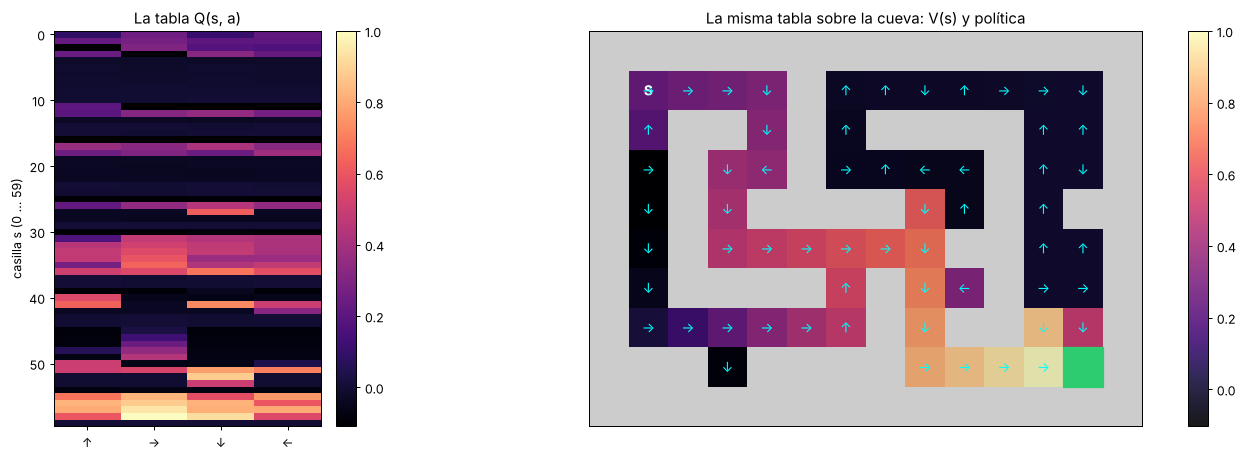

In [4]:
GAMMA = 0.95
env = CaveEnv(step_reward=-0.01, max_steps=100)   # pequeño castigo por paso: apura al agente
Q_tab, _ = q_learning_tabular(env, episodios=300, gamma=GAMMA)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw=dict(width_ratios=[1, 3]))
im = axes[0].imshow(Q_tab, aspect="auto", cmap="magma")
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(ACTION_NAMES)
axes[0].set_ylabel(f"casilla s (0 … {env.nS - 1})"); axes[0].set_title("La tabla Q(s, a)")
plt.colorbar(im, ax=axes[0], fraction=0.08)
env.plot(values=Q_tab.max(1), policy=Q_tab.argmax(1), ax=axes[1], title="La misma tabla sobre la cueva: V(s) y política")
plt.tight_layout();

Una tabla es una función que **memoriza** un número por entrada:

$$
Q:\ (s, a) \longmapsto \text{valor} \qquad\Longrightarrow\qquad Q_\theta:\ \text{observación}(s) \longmapsto \big(Q(s,\uparrow), Q(s,\rightarrow), Q(s,\downarrow), Q(s,\leftarrow)\big)
$$

Una red neuronal $Q_\theta$ con parámetros $\theta$ es otra forma de representar esa función. La diferencia: la tabla
tiene un casillero *independiente* por estado; la red **comparte** parámetros entre estados parecidos, así que lo que
aprende en uno se *generaliza* a otros. Es lo mismo que pasa en visión (una red reconoce un gato que nunca vio) y en
NLP (los *embeddings* acercan palabras parecidas).

## Paso 1 — Una red con entrada one-hot **es** una tabla

Codificamos el estado como un vector *one-hot* (*one-hot encoding*): todo ceros salvo un 1 en la posición de la
casilla (`env.observe(kind="onehot")`). Tomamos la red más simple: una capa lineal sin sesgo, $Q_\theta(s) = W\,x_s$.
Multiplicar por un one-hot **selecciona una columna** de $W$: la columna $s$ son los 4 valores de la casilla $s$.
O sea, $W$ *es* la tabla traspuesta.

Lo comprobamos: le damos **las mismas 3.000 transiciones** a Q-learning tabular ($\alpha = 0.5$) y a la red entrenada
con descenso por gradiente (*SGD*, tasa de aprendizaje 0.5, pérdida $\tfrac12(Q_\theta(s,a) - y)^2$).

Parámetros de la red: 240  =  casillas × acciones = 60 × 4
Diferencia máxima entre tabla y red: 0.0e+00


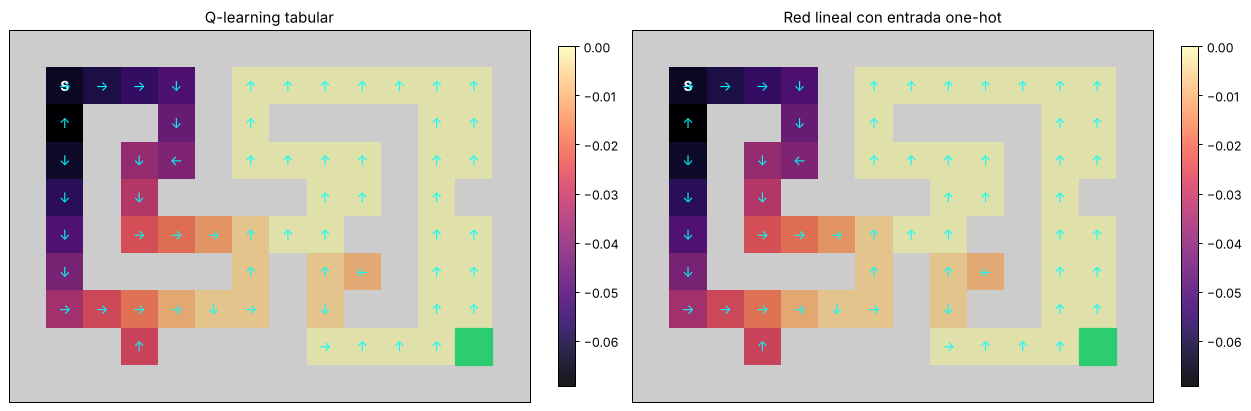

In [5]:
trans = transiciones_al_azar(env, n=3000)
Q_t = q_tabla(env, trans, alpha=0.5, gamma=GAMMA)
Q_r, red_lineal = q_red_onehot(env, trans, alpha=0.5, gamma=GAMMA)

print(f"Parámetros de la red: {red_lineal.weight.numel()}  =  casillas × acciones = {env.nS} × 4")
print(f"Diferencia máxima entre tabla y red: {np.abs(Q_t - Q_r).max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
env.plot(values=Q_t.max(1), policy=Q_t.argmax(1), ax=axes[0], title="Q-learning tabular")
env.plot(values=Q_r.max(1), policy=Q_r.argmax(1), ax=axes[1], title="Red lineal con entrada one-hot")
plt.tight_layout();

Dos dibujos idénticos, diferencia 0 (como mucho, error de redondeo). La cuenta que lo explica: el gradiente de
$\tfrac12(Q_\theta(s,a)-y)^2$ respecto de $W_{a,s}$ es $(Q_\theta(s,a)-y)\cdot 1$, y respecto de cualquier otra entrada es 0
(por el one-hot). Un paso de SGD queda

$$
W_{a,s} \leftarrow W_{a,s} + \alpha\,\big(y - W_{a,s}\big)
$$

que es **exactamente** la regla de Q-learning de la clase 4. **Q-learning tabular es un caso particular de una red.**

Pero el one-hot no generaliza: la casilla 17 no sabe nada de la 18. Para eso necesitamos una entrada más rica y una
red con capas ocultas.

## Paso 2 — DQN: posición + bigotes

Le damos a la red una observación que se parece más a lo que "siente" el jugador en la cueva a oscuras
(`env.observe(kind="coords+touch")`): **6 números**, la fila y la columna normalizadas, y 4 **bigotes**
(arriba, derecha, abajo, izquierda) que valen 1 si hay pared pegada.

In [6]:
for s in [env.start, 5, env.goal]:
    fila, col = env.free[s]
    o = env.observe(s, kind="coords+touch")
    bigotes = " ".join(f"{n}:{int(b)}" for n, b in zip(ACTION_NAMES, o[2:]))
    print(f"casilla ({fila},{col}) -> posición = ({o[0]:.2f}, {o[1]:.2f})   bigotes  {bigotes}")

casilla (1,1) -> posición = (0.11, 0.08)   bigotes  ↑:1 →:0 ↓:0 ←:1
casilla (1,7) -> posición = (0.11, 0.54)   bigotes  ↑:1 →:0 ↓:1 ←:0
casilla (8,12) -> posición = (0.89, 0.92)   bigotes  ↑:0 →:1 ↓:1 ←:0


Pasar de la tabla a la red no es solo "cambiar la tabla por una red". Si lo hacemos ingenuamente, el aprendizaje es
inestable. DQN agrega tres ingredientes:

1. **Memoria de repetición** (*experience replay*): guardamos las transiciones $(s,a,r,s')$ en un *buffer* y entrenamos
   con **lotes al azar** de esa memoria. Así los ejemplos no están correlacionados (pasos consecutivos son casi iguales)
   y cada experiencia se reusa muchas veces.
2. **Red objetivo** (*target network*): el objetivo $y = r + \gamma \max_{a'} Q_{\bar\theta}(s',a')$ se calcula con una
   **copia congelada** de la red, que se actualiza cada tantos pasos. Si no, la red persigue un blanco que se mueve con ella.
3. **ε decreciente**: al principio casi todo al azar (explorar), y ε baja de a poco hasta 0.05 (explotar).

La red es un perceptrón multicapa (*MLP*) chico: 6 → 64 → 64 → 4. Recompensa: +1 en la salida y −0.01 por paso
(una ayuda para que aprenda en pocos segundos de CPU). Entrenamos 150 episodios.

Entrenamiento: 7,686 pasos en 5.7 s


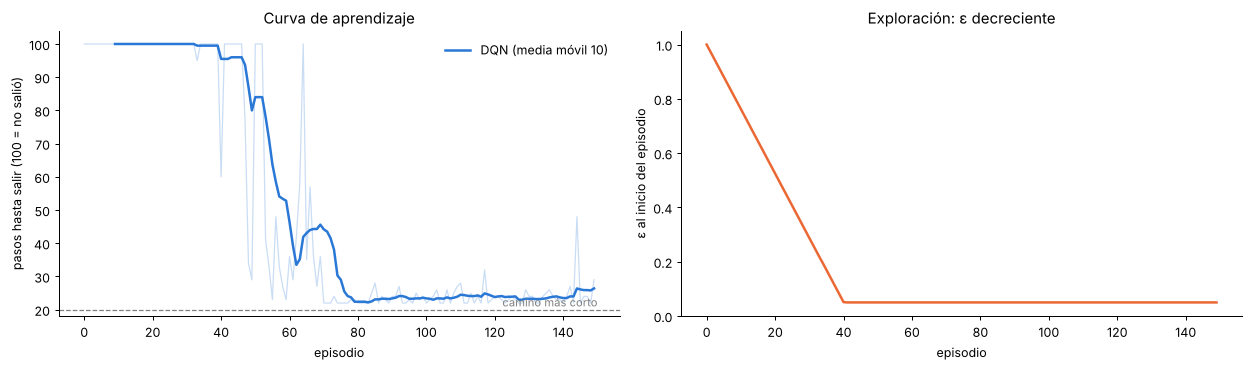

In [7]:
t0 = time.time()
res = dqn(env, obs="coords+touch", episodios=150, gamma=GAMMA, seed=0)
print(f"Entrenamiento: {res['pasos']:,} pasos en {time.time() - t0:.1f} s")

V_star, _ = iteracion_de_valor(env, gamma=GAMMA)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
ax.plot(res["largos"], color=AZUL, alpha=0.25, lw=1)
ax.plot(np.arange(9, len(res["largos"])), media_movil(res["largos"]), color=AZUL, lw=2, label="DQN (media móvil 10)")
ax.axhline(20, color="gray", ls="--", lw=1); ax.text(len(res["largos"]), 21, "camino más corto", ha="right", color="gray", fontsize=9)
ax.set_xlabel("episodio"); ax.set_ylabel("pasos hasta salir (100 = no salió)"); ax.set_title("Curva de aprendizaje")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
ax = axes[1]
ax.plot(res["eps"], color=NARANJA, lw=2)
ax.set_xlabel("episodio"); ax.set_ylabel("ε al inicio del episodio"); ax.set_title("Exploración: ε decreciente")
ax.set_ylim(0, 1.05); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout();

Al principio los episodios llegan al tope de 100 pasos (no sale). A medida que ε baja y la red aprende, el largo cae
hasta cerca del camino más corto (20 pasos). Recordemos que en esta cueva chica un agente al azar sale ~5% de las veces:
acá la exploración no es el problema (eso fue la clase 5); el desafío es **aprender con una red**.

La pérdida que minimiza DQN, para un lote de transiciones de la memoria:

$$
\mathcal{L}(\theta) = \Big(\underbrace{r + \gamma \max_{a'} Q_{\bar\theta}(s',a')}_{y\ \text{(red objetivo, congelada)}} - Q_\theta(s,a)\Big)^2
$$

Es el error TD de la clase 4, convertido en una pérdida de regresión como las de cualquier red.

## Paso 3 — ¿Qué aprendió la red?

Evaluamos la red en **todas** las casillas y pintamos $V(s) = \max_a Q_\theta(s,a)$ con la política (flechas),
al lado del $V^*$ exacto que calculamos con el modelo en la clase 3 (iteración de valor).
Abajo, la trayectoria que sigue la red sin explorar (*greedy*).

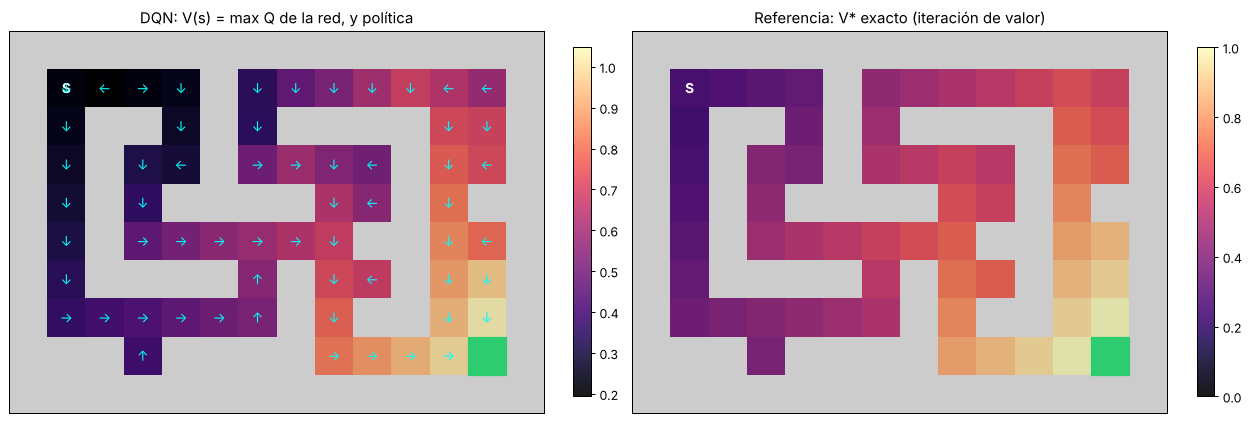

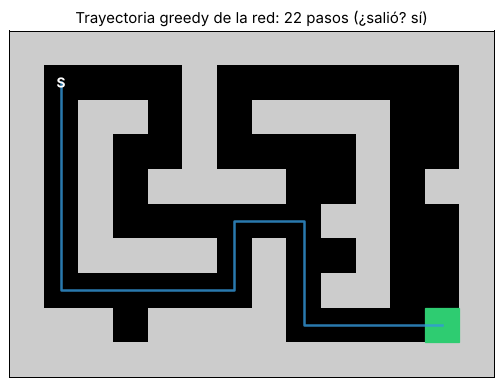

In [8]:
Q_red = q_de_la_red(env, res["red"], res["obs"])
camino, salio = trayectoria_greedy(env, res["red"], res["obs"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
env.plot(values=Q_red.max(1), policy=Q_red.argmax(1), ax=axes[0], title="DQN: V(s) = max Q de la red, y política")
env.plot(values=V_star, ax=axes[1], title="Referencia: V* exacto (iteración de valor)")
plt.tight_layout()

ax = env.plot(path=camino, title=f"Trayectoria greedy de la red: {len(camino) - 1} pasos (¿salió? {'sí' if salio else 'no'})");

El mapa de la red se parece al $V^*$ exacto: valores altos cerca de la salida, que bajan con la distancia, y flechas
que forman un camino. **La red nunca vio el mapa ni el modelo**: solo posiciones, bigotes y recompensas.

### ✍️ Ejercicio

Cambiá `obs="coords+touch"` por `obs="coords"` (sin bigotes) y volvé a entrenar. ¿Aprende igual? ¿Dónde se equivoca
la política? (Pista: con solo la posición, la red tiene que "dibujar" las paredes con su función.)

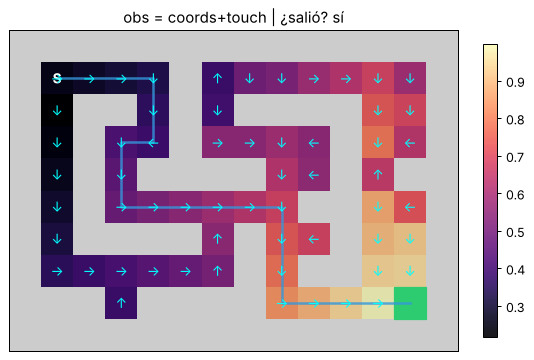

In [9]:
# TODO: probá obs="coords" y/o otra semilla
prueba = dqn(env, obs="coords+touch", episodios=150, gamma=GAMMA, seed=1)
Qp = q_de_la_red(env, prueba["red"], prueba["obs"])
cam, ok = trayectoria_greedy(env, prueba["red"], prueba["obs"])
env.plot(values=Qp.max(1), policy=Qp.argmax(1), path=cam, title=f"obs = {prueba['obs']} | ¿salió? {'sí' if ok else 'no'}");

## Paso 4 — Generalización: valores donde casi no estuvo

Durante el entrenamiento, la política se concentró en el camino a la salida y muchas casillas se visitaron poco.
Comparamos tres mapas:

1. cuántas veces se visitó cada casilla (log; negro = nunca);
2. $V(s)$ de un **Q-learning tabular** con el mismo presupuesto y el mismo ε;
3. $V(s)$ de la **red**.

Casillas visitadas menos de 20 veces por DQN: 23 de 60
Error medio |V - V*| en esas casillas poco visitadas:  tabla = 0.660   red = 0.044


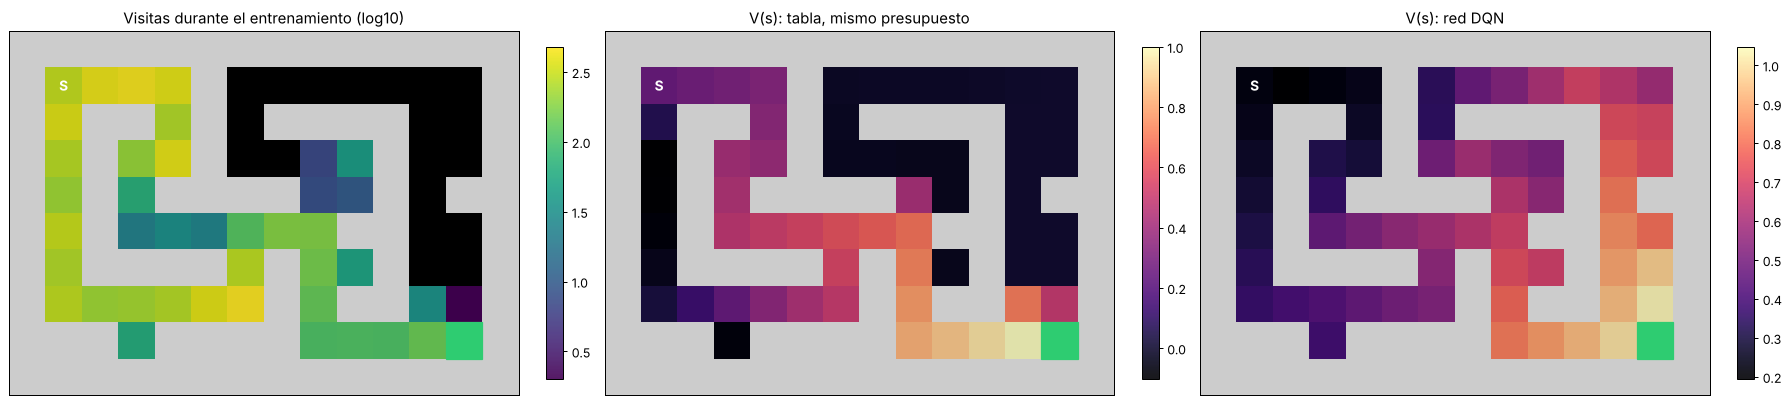

In [10]:
Q_tab2, N_tab = q_learning_tabular(env, episodios=150, gamma=GAMMA)
pocas = res["N"] < 20
print(f"Casillas visitadas menos de 20 veces por DQN: {pocas.sum()} de {env.nS}")
err_red = np.abs(Q_red.max(1) - V_star)[pocas].mean()
err_tab = np.abs(Q_tab2.max(1) - V_star)[N_tab < 20].mean()
print(f"Error medio |V - V*| en esas casillas poco visitadas:  tabla = {err_tab:.3f}   red = {err_red:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(20, 4.6))
mapa_visitas(env, res["N"], axes[0], "Visitas durante el entrenamiento (log10)")
env.plot(values=Q_tab2.max(1), ax=axes[1], title="V(s): tabla, mismo presupuesto")
env.plot(values=Q_red.max(1), ax=axes[2], title="V(s): red DQN")
plt.tight_layout();

La tabla solo sabe algo de las casillas que visitó *muchas* veces: en las demás quedó cerca de su valor inicial y el
mapa se ve "manchado". La red, en cambio, da un valor **razonable en todas**, porque casillas cercanas tienen entradas
parecidas y comparten parámetros.

Una aclaración honesta: en esta cueva la red tiene **más** parámetros que la tabla (~5.000 contra 240). La ventaja no
está en el tamaño acá, sino en que **la cantidad de parámetros no crece con la cantidad de estados**, y en que lo
aprendido se transfiere a estados parecidos. Con pixeles, esa es la única opción.

## Paso 5 — Ablación: DQN sin memoria de repetición

¿Hace falta el *replay buffer*? Entrenamos la misma red, mismos pasos, pero aprendiendo **solo de la última transición**
(como hacía Q-learning tabular), sin memoria.

Sin replay: 9.7 s


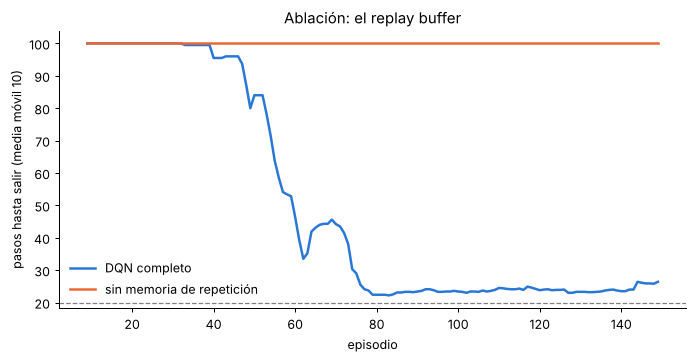

In [11]:
t0 = time.time()
res_sin = dqn(env, obs="coords+touch", episodios=150, gamma=GAMMA, seed=0, usar_replay=False)
print(f"Sin replay: {time.time() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(9, 4))
for r_, nombre, color in [(res, "DQN completo", AZUL), (res_sin, "sin memoria de repetición", NARANJA)]:
    ax.plot(np.arange(9, len(r_["largos"])), media_movil(r_["largos"]), lw=2, color=color, label=nombre)
ax.axhline(20, color="gray", ls="--", lw=1)
ax.set_xlabel("episodio"); ax.set_ylabel("pasos hasta salir (media móvil 10)")
ax.set_title("Ablación: el replay buffer"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False);

Sin memoria, la red aprende de una transición a la vez, siempre de la zona donde está parada: cada paso de gradiente
"pisa" lo aprendido en otra parte (*olvido catastrófico*, *catastrophic forgetting*) y no llega a una política que salga.
Con la tabla esto no pasaba porque cada casillero es independiente: **la generalización tiene un precio**,
y el replay es parte de cómo se paga.

(Si quieren probar sin red objetivo: `usar_objetivo=False`. En esta cueva chica suele funcionar igual; en Atari, sin
ella el entrenamiento diverge con frecuencia.)

## Cierre — De la cueva a Atari, y de Atari a ChatGPT

**DQN en Atari** (Mnih et al., *Nature* 2015): la misma receta de hoy (replay + red objetivo + ε decreciente), con
otra observación: las **últimas 4 pantallas** reducidas a 84×84 grises, y una **red convolucional** (la de visión) en vez
de nuestro MLP. Con **los mismos hiperparámetros** jugó 49 juegos distintos, y en más de la mitad superó a un jugador
humano profesional. En *Montezuma's Revenge* sacó **0 puntos**: el problema de exploración de la clase 5.

**Lo que viene después.** DQN aprende $Q$ y deriva la política con un $\arg\max$. Eso funciona con pocas acciones
discretas. Otra familia aprende **directamente la política** $\pi_\theta(a \mid s)$ empujando hacia arriba la probabilidad
de las acciones que salieron bien: **gradiente de política** (*policy gradient*). Su versión más usada es **PPO**
(*Proximal Policy Optimization*, Schulman et al. 2017).

Y acá está el puente: un modelo de lenguaje *es* una política $\pi_\theta(\text{próximo token} \mid \text{texto})$.
**RLHF** (*Reinforcement Learning from Human Feedback*) la ajusta con PPO usando como recompensa una red entrenada con
preferencias humanas. Así se pasó de GPT-3 a ChatGPT.

## Preguntas para pensar

1. En el Paso 1 la red one-hot era idéntica a la tabla. ¿Qué cambiarías en la entrada para que dos casillas vecinas
   "se ayuden"? ¿Por qué eso puede ser malo si hay una pared entre ellas?
2. La memoria de repetición reusa experiencias viejas, generadas por una política anterior. ¿Por qué Q-learning puede
   aprender de eso (es *off-policy*) y SARSA no tanto?
3. Si el agente de la cueva recibiera la imagen del mapa entero, ¿qué arquitectura usarías? ¿Y si recibiera una
   descripción en texto ("pasillo hacia la derecha, pared arriba")?

## Próxima clase

Clase 7: **redes recurrentes**. Hasta acá la red recibía la casilla, pero el jugador a ciegas no la ve: solo siente
los choques. Cuando la observación no alcanza para saber dónde estás, la red necesita memoria.